#OPD Data Preparation and Exploratory Data Analysis



## 0. Setup and load the file

Upload `HospitalOPD-noname.csv` to Colab when prompted, or change `DATA_PATH` to the file location on your computer.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# In Google Colab, uncomment these two lines to upload the CSV:
# from google.colab import files
# uploaded = files.upload()

DATA_PATH = Path("/content/HospitalOPD-noname.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Upload HospitalOPD-noname.csv to Colab "
        "or update DATA_PATH to its correct location."
    )

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Shape: 62,422 rows × 25 columns


,record_no,patient_id,Unnamed: 2,appointment_id,appointment_start_datetime,prescription_doctor_id,prescription_doctor_name,prescription_order_id,prescription_start_datetime,prescription_end_datetime,...,imaging_result_id,imaging_name,imaging_start_datetime,imaging_end_datetime,pharmacy_sale_line_id,medicine_name,pharmacy_start_datetime,pharmacy_end_datetime,flow_code,flow_name
0,1,10,NaN,445911,3/30/2026 5:36,225,Admin,106357,3/30/2026 5:38,3/30/2026 6:48,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
1,2,57,NaN,335085,10/14/2025 5:23,193,Dr. Abrar Ahmed Bhatti,43515,10/14/2025 5:39,10/14/2025 5:53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
2,3,57,NaN,335085,10/14/2025 5:23,193,Dr. Abrar Ahmed Bhatti,43541,10/14/2025 6:11,10/14/2025 6:24,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
3,4,60,NaN,322358,9/25/2025 13:36,195,Dr. Anique Ahmed,34654,9/25/2025 13:50,9/25/2025 13:51,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription
4,5,72,NaN,337714,10/17/2025 6:40,202,Dr. Mehreen Batool Bokhari,45263,10/17/2025 6:49,10/17/2025 6:49,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Appointment → Prescription


## 1. Understand the source dataset

In [2]:
print("Column names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nMissing values:")
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing)
print("\nExact duplicate rows:", df.duplicated().sum())
print("Unique appointment IDs:", df["appointment_id"].nunique(dropna=True))
print("Unique patient IDs:", df["patient_id"].nunique(dropna=True))

Column names:
['record_no', 'patient_id', 'Unnamed: 2', 'appointment_id', 'appointment_start_datetime', 'prescription_doctor_id', 'prescription_doctor_name', 'prescription_order_id', 'prescription_start_datetime', 'prescription_end_datetime', 'lab_id', 'lab_name', 'lab_start_datetime', 'lab_end_datetime', 'imaging_request_id', 'imaging_result_id', 'imaging_name', 'imaging_start_datetime', 'imaging_end_datetime', 'pharmacy_sale_line_id', 'medicine_name', 'pharmacy_start_datetime', 'pharmacy_end_datetime', 'flow_code', 'flow_name']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62422 entries, 0 to 62421
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   record_no                    62422 non-null  int64  
 1   patient_id                   62422 non-null  int64  
 2   Unnamed: 2                   0 non-null      float64
 3   appointment_id             

,missing_count,missing_percent
Unnamed: 2,62422,100.00
medicine_name,62120,99.52
pharmacy_sale_line_id,62120,99.52
pharmacy_end_datetime,62120,99.52
pharmacy_start_datetime,62120,99.52
imaging_end_datetime,56909,91.17
imaging_name,56899,91.15
imaging_result_id,56899,91.15
imaging_request_id,56899,91.15
imaging_start_datetime,56899,91.15



Exact duplicate rows: 0
Unique appointment IDs: 49912
Unique patient IDs: 39442


### Initial observations for this supplied file
The supplied file has **62,422 rows and 25 columns**. It contains **49,912 unique appointment IDs** and **39,442 unique patient IDs**. `Unnamed: 2` is completely empty. Many lab, imaging and pharmacy fields are sparse because those services are not recorded for every appointment. Do not fill those service fields with invented values; they are not required to count appointment starts.

## 2. Select relevant fields and parse appointment timestamps

In [3]:
required = ["appointment_id", "patient_id", "appointment_start_datetime"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise KeyError(f"Required columns missing from file: {missing_required}")

# Keep the source dataframe unchanged; create a focused working copy.
work = df[required].copy()
work["appointment_start_datetime"] = pd.to_datetime(
    work["appointment_start_datetime"], errors="coerce"
)

print("Rows with invalid/missing appointment timestamp:",
      work["appointment_start_datetime"].isna().sum())
print("Earliest valid timestamp:", work["appointment_start_datetime"].min())
print("Latest valid timestamp:", work["appointment_start_datetime"].max())

# Drop only records that cannot be assigned to an appointment or timestamp.
work = work.dropna(subset=["appointment_id", "appointment_start_datetime"]).copy()

Rows with invalid/missing appointment timestamp: 0
Earliest valid timestamp: 2024-04-25 11:12:00
Latest valid timestamp: 2026-04-07 08:03:00


## 3. Create one row per appointment (avoid double counting)

One appointment can occupy multiple source rows because the same appointment may be associated with multiple prescription/service records. The supplied data has no exact duplicate rows, but repeated appointment IDs exist. Check whether an appointment ID maps to multiple patients or timestamps before deduplicating.

In [4]:
appointment_checks = (
    work.groupby("appointment_id")
        .agg(source_rows=("appointment_id", "size"),
             distinct_patients=("patient_id", "nunique"),
             distinct_start_times=("appointment_start_datetime", "nunique"))
)
display(appointment_checks.describe())
print("Appointment IDs linked to >1 patient:",
      (appointment_checks["distinct_patients"] > 1).sum())
print("Appointment IDs linked to >1 start time:",
      (appointment_checks["distinct_start_times"] > 1).sum())

# For this project, count each appointment_id once. The source is sorted so
# the first available record is retained; conflicting IDs are reported above.
appointments = (
    work.sort_values("appointment_start_datetime")
        .drop_duplicates(subset="appointment_id", keep="first")
        .copy()
)
appointments = appointments.sort_values("appointment_start_datetime").reset_index(drop=True)
print(f"Appointment-level rows: {len(appointments):,}")
print("Unique appointment IDs after deduplication:", appointments["appointment_id"].nunique())
display(appointments.head())

,source_rows,distinct_patients,distinct_start_times
count,49912.000000,49912.0,49912.0
mean,1.250641,1.0,1.0
std,1.076733,0.0,0.0
min,1.000000,1.0,1.0
25%,1.000000,1.0,1.0
50%,1.000000,1.0,1.0
75%,1.000000,1.0,1.0
max,28.000000,1.0,1.0


Appointment IDs linked to >1 patient: 0
Appointment IDs linked to >1 start time: 0
Appointment-level rows: 49,912
Unique appointment IDs after deduplication: 49912


,appointment_id,patient_id,appointment_start_datetime
0,317,849,2024-04-25 11:12:00
1,756,92441,2024-04-27 12:32:00
2,1694,83747,2024-04-29 13:37:00
3,2182,93374,2024-04-30 10:30:00
4,2948,58756,2024-05-02 06:10:00


## 4. Extract time features

In [5]:
ts = appointments["appointment_start_datetime"]
appointments["date"] = ts.dt.normalize()
appointments["hour"] = ts.dt.hour
appointments["day"] = ts.dt.day
appointments["weekday"] = ts.dt.day_name()
appointments["weekday_num"] = ts.dt.dayofweek  # Monday=0, Sunday=6
appointments["month"] = ts.dt.month_name()
appointments["month_num"] = ts.dt.month
appointments["year"] = ts.dt.year
appointments["year_month"] = ts.dt.to_period("M").astype(str)

display(appointments.head())
print("Appointment date range:", appointments["date"].min(), "to", appointments["date"].max())

,appointment_id,patient_id,appointment_start_datetime,date,hour,day,weekday,weekday_num,month,month_num,year,year_month
0,317,849,2024-04-25 11:12:00,2024-04-25,11,25,Thursday,3,April,4,2024,2024-04
1,756,92441,2024-04-27 12:32:00,2024-04-27,12,27,Saturday,5,April,4,2024,2024-04
2,1694,83747,2024-04-29 13:37:00,2024-04-29,13,29,Monday,0,April,4,2024,2024-04
3,2182,93374,2024-04-30 10:30:00,2024-04-30,10,30,Tuesday,1,April,4,2024,2024-04
4,2948,58756,2024-05-02 06:10:00,2024-05-02,6,2,Thursday,3,May,5,2024,2024-05


Appointment date range: 2024-04-25 00:00:00 to 2026-04-07 00:00:00


## 5. Aggregate appointments into hourly and daily counts

The hourly series is continuous between the first and last observed appointment. Hours with no appointment record are set to zero for the time-series table, but this is an analytical assumption—not proof the hospital was open and had zero arrivals. Check operational calendars or source-system completeness with the project supervisor before treating all zero hours as genuine zero demand.

In [6]:
# Count unique appointments per clock hour.
hourly_counts = (
    appointments.set_index("appointment_start_datetime")
        .resample("h")["appointment_id"]
        .nunique()
        .rename("patient_count")
        .to_frame()
)

# Create a complete hourly index; absent appointment records become 0.
full_hour_index = pd.date_range(
    start=hourly_counts.index.min().floor("h"),
    end=hourly_counts.index.max().floor("h"),
    freq="h"
)
hourly_data = hourly_counts.reindex(full_hour_index, fill_value=0)
hourly_data.index.name = "datetime_hour"
hourly_data = hourly_data.reset_index()
hourly_data["hour"] = hourly_data["datetime_hour"].dt.hour
hourly_data["date"] = hourly_data["datetime_hour"].dt.normalize()
hourly_data["weekday"] = hourly_data["datetime_hour"].dt.day_name()
hourly_data["month"] = hourly_data["datetime_hour"].dt.month_name()

# Daily counts from unique appointments (not sum of duplicated source rows).
daily_data = (
    appointments.groupby("date").size()
        .rename("daily_patient_count")
        .reset_index()
)

print("Hourly rows:", f"{len(hourly_data):,}")
print("Daily rows:", f"{len(daily_data):,}")
print("Total appointments represented in hourly counts:",
      int(hourly_data["patient_count"].sum()))
display(hourly_data.head())
display(daily_data.head())

Hourly rows: 17,086
Daily rows: 391
Total appointments represented in hourly counts: 49912


,datetime_hour,patient_count,hour,date,weekday,month
0,2024-04-25 11:00:00,1,11,2024-04-25,Thursday,April
1,2024-04-25 12:00:00,0,12,2024-04-25,Thursday,April
2,2024-04-25 13:00:00,0,13,2024-04-25,Thursday,April
3,2024-04-25 14:00:00,0,14,2024-04-25,Thursday,April
4,2024-04-25 15:00:00,0,15,2024-04-25,Thursday,April


,date,daily_patient_count
0,2024-04-25,1
1,2024-04-27,1
2,2024-04-29,1
3,2024-04-30,1
4,2024-05-02,1


## 6. Data quality checks for the aggregated data

In [7]:
assert appointments["appointment_id"].is_unique, "Appointment IDs are not unique."
assert hourly_data["datetime_hour"].is_monotonic_increasing
assert (hourly_data["patient_count"] >= 0).all()
assert int(hourly_data["patient_count"].sum()) == len(appointments), \
    "Hourly total does not reconcile to appointment-level records."

observed_hours = hourly_counts.shape[0]
complete_hours = len(hourly_data)
zero_hours = int((hourly_data["patient_count"] == 0).sum())
print(f"Observed hours with at least one appointment: {observed_hours:,}")
print(f"Hours in continuous series: {complete_hours:,}")
print(f"Zero-count hours after reindexing: {zero_hours:,}")
print("These zero-count hours require a data-coverage/opening-hours check.")

Observed hours with at least one appointment: 17,086
Hours in continuous series: 17,086
Zero-count hours after reindexing: 12,428
These zero-count hours require a data-coverage/opening-hours check.


## 7. Exploratory Data Analysis (EDA)

### Graph 1 — Average appointments by hour of day

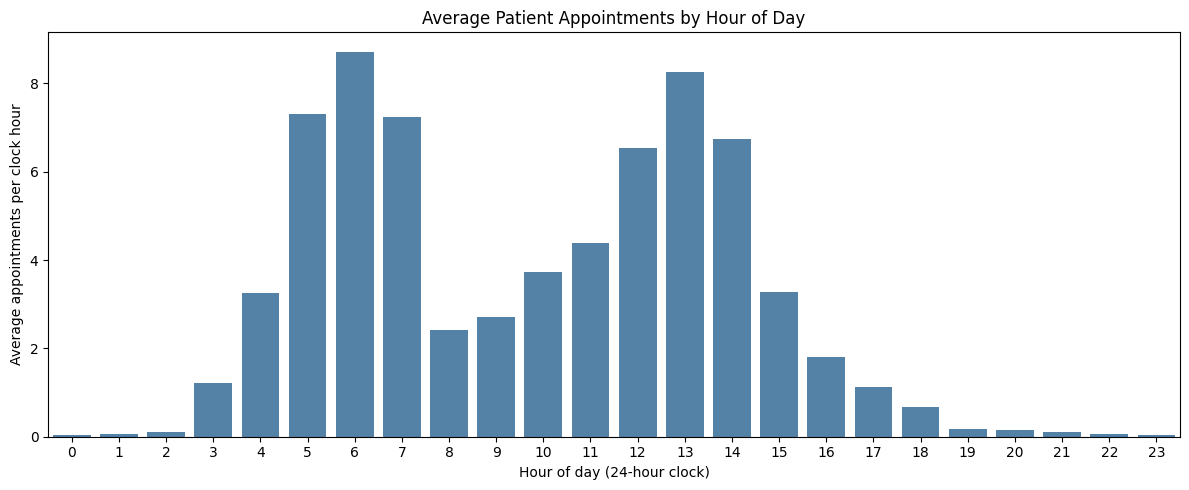

Busiest average hour: 6 with 8.72 appointments/hour
Lowest average hour: 23 with 0.04 appointments/hour


In [8]:
hourly_avg = hourly_data.groupby("hour")["patient_count"].mean().reindex(range(24), fill_value=0)
plt.figure(figsize=(12, 5))
sns.barplot(x=hourly_avg.index, y=hourly_avg.values, color="steelblue")
plt.title("Average Patient Appointments by Hour of Day")
plt.xlabel("Hour of day (24-hour clock)")
plt.ylabel("Average appointments per clock hour")
plt.xticks(range(24))
plt.tight_layout()
plt.show()
print("Busiest average hour:", int(hourly_avg.idxmax()), "with", round(hourly_avg.max(), 2), "appointments/hour")
print("Lowest average hour:", int(hourly_avg.idxmin()), "with", round(hourly_avg.min(), 2), "appointments/hour")

### Graph 2 — Average daily appointments by weekday

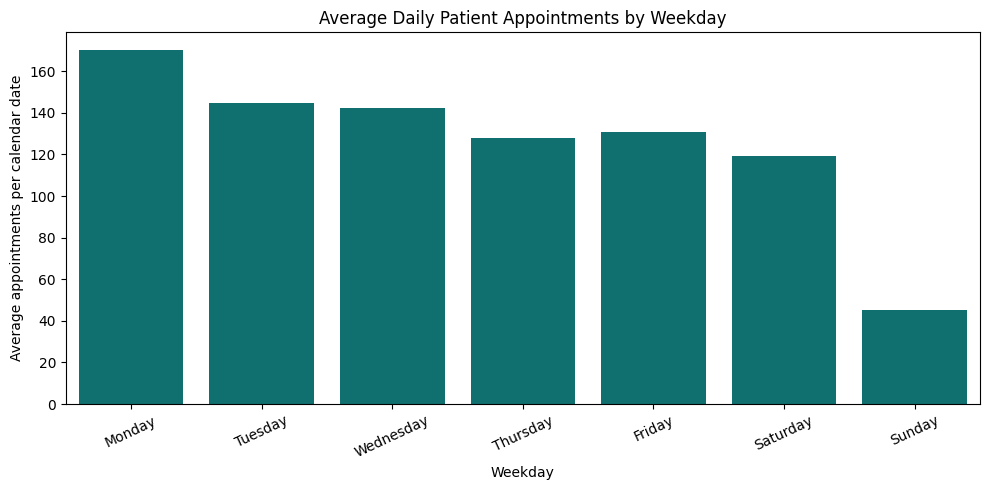

,average_daily_appointments
weekday,
Monday,170.203390
Tuesday,144.779661
Wednesday,142.345455
Thursday,127.830508
Friday,130.660714
Saturday,119.074074
Sunday,45.102041


In [9]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_data["weekday"] = daily_data["date"].dt.day_name()
weekday_avg = daily_data.groupby("weekday")["daily_patient_count"].mean().reindex(weekday_order)
plt.figure(figsize=(10, 5))
sns.barplot(x=weekday_avg.index, y=weekday_avg.values, color="teal")
plt.title("Average Daily Patient Appointments by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average appointments per calendar date")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()
display(weekday_avg.rename("average_daily_appointments").to_frame())

### Graph 3 — Monthly appointment totals

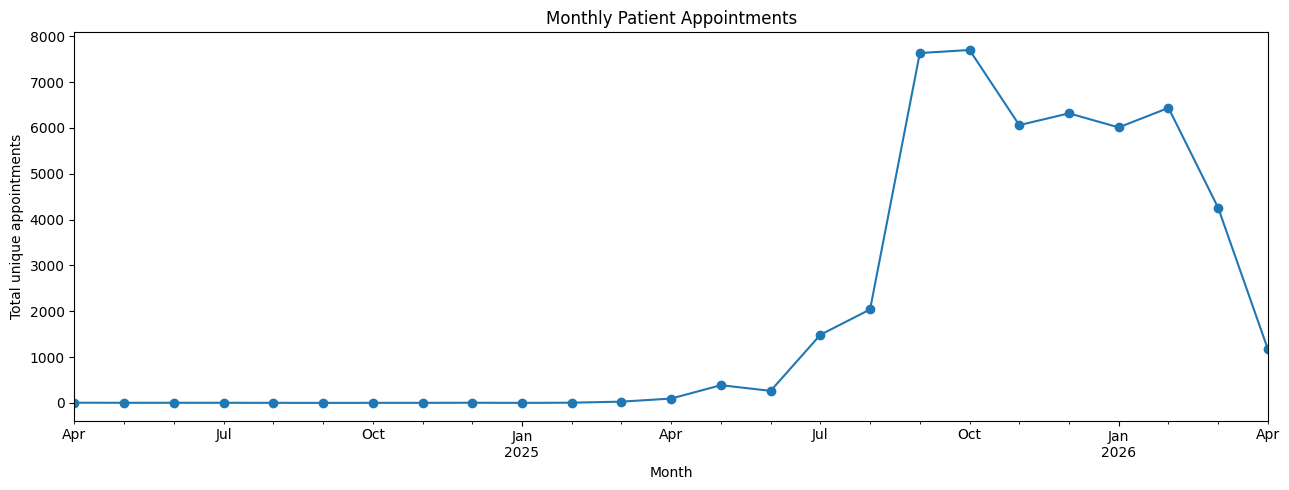

,monthly_appointments
appointment_start_datetime,
2024-04-01,4
2024-05-01,2
2024-06-01,2
2024-07-01,2
2024-08-01,1
2024-09-01,0
2024-10-01,1
2024-11-01,1
2024-12-01,3


Note: first and last months may be partial because the dataset starts/ends mid-month.


In [10]:
monthly_data = (
    appointments.set_index("appointment_start_datetime")
        .resample("MS")["appointment_id"].nunique()
        .rename("monthly_appointments")
)
plt.figure(figsize=(13, 5))
monthly_data.plot(marker="o")
plt.title("Monthly Patient Appointments")
plt.xlabel("Month")
plt.ylabel("Total unique appointments")
plt.tight_layout()
plt.show()
display(monthly_data.to_frame())
print("Note: first and last months may be partial because the dataset starts/ends mid-month.")

### Graph 4 — Daily appointment counts over time

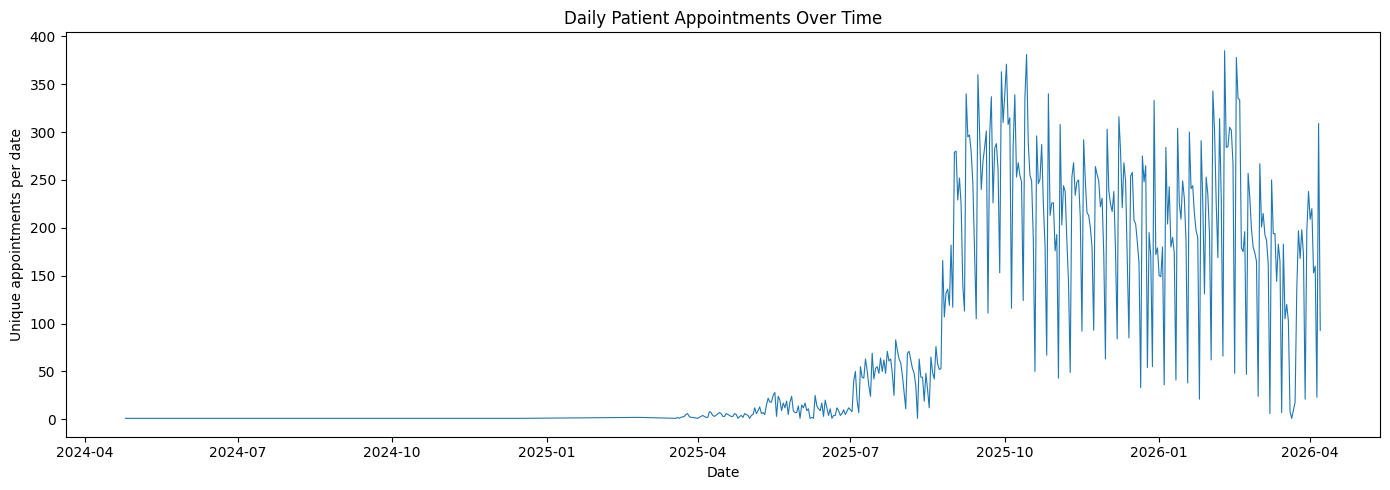

In [11]:
plt.figure(figsize=(14, 5))
plt.plot(daily_data["date"], daily_data["daily_patient_count"], linewidth=0.8)
plt.title("Daily Patient Appointments Over Time")
plt.xlabel("Date")
plt.ylabel("Unique appointments per date")
plt.tight_layout()
plt.show()

### Graph 5 — Weekday-by-hour heatmap

Values below are the **average appointments per matching weekday/hour across dates**, not total counts. This makes weekday comparisons more interpretable when the dataset contains different numbers of each weekday.

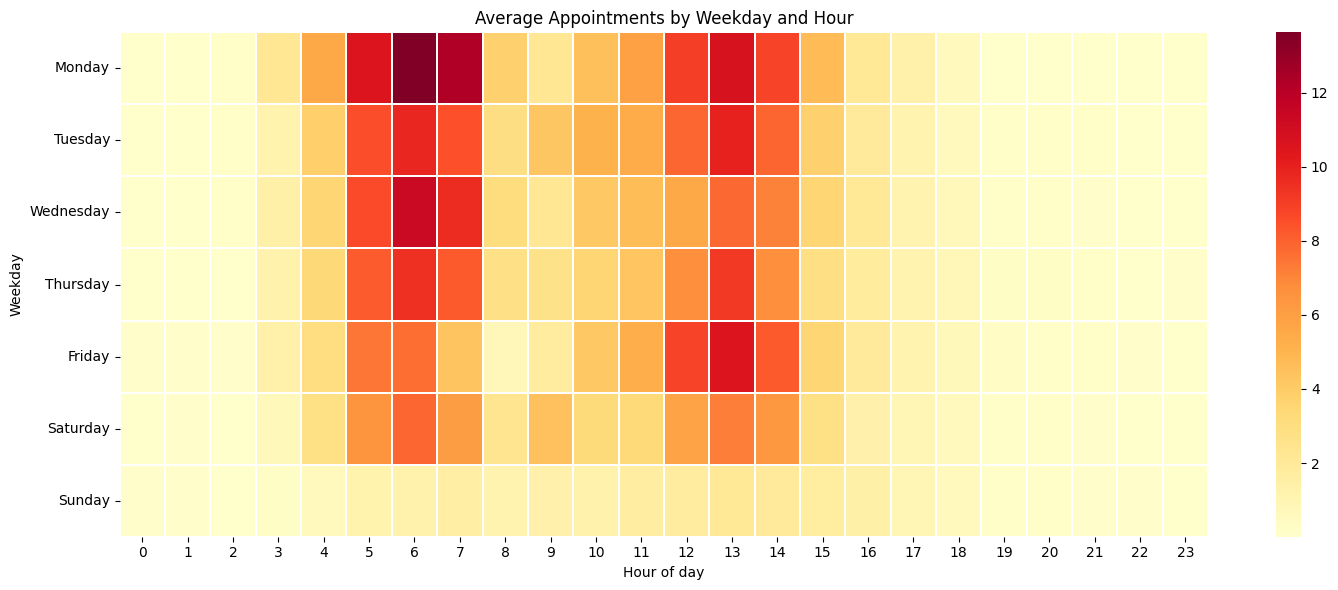

In [12]:
appointments["weekday"] = appointments["appointment_start_datetime"].dt.day_name()
appointments["hour"] = appointments["appointment_start_datetime"].dt.hour
# First calculate count for each calendar date and hour, including dates with no
# appointments in that hour; then average those counts by weekday and hour.
date_hour = (
    appointments.groupby(["date", "weekday", "hour"]).size()
        .rename("appointments")
        .reset_index()
)
all_dates = pd.date_range(appointments["date"].min(), appointments["date"].max(), freq="D")
all_combinations = pd.MultiIndex.from_product(
    [all_dates, range(24)], names=["date", "hour"]
).to_frame(index=False)
all_combinations["weekday"] = all_combinations["date"].dt.day_name()
date_hour_complete = all_combinations.merge(
    date_hour, on=["date", "weekday", "hour"], how="left"
)
date_hour_complete["appointments"] = date_hour_complete["appointments"].fillna(0)
heatmap_data = (
    date_hour_complete.groupby(["weekday", "hour"])["appointments"]
        .mean().unstack("hour").reindex(weekday_order)
)
plt.figure(figsize=(15, 6))
sns.heatmap(heatmap_data, cmap="YlOrRd", linewidths=0.2)
plt.title("Average Appointments by Weekday and Hour")
plt.xlabel("Hour of day")
plt.ylabel("Weekday")
plt.tight_layout()
plt.show()

## 8. Statistical summary and peak periods

In [13]:
hourly_stats = hourly_data["patient_count"].describe()
print("Hourly patient-count statistics:")
display(hourly_stats.to_frame(name="patient_count"))

# Hour with highest mean count across all calendar days in the dataset.
print("Busiest hour (average):", int(hourly_avg.idxmax()))
print("Least busy hour (average):", int(hourly_avg.idxmin()))
print("Busiest weekday (average daily count):", weekday_avg.idxmax())
print("Least busy weekday (average daily count):", weekday_avg.idxmin())
print("Maximum single-hour count:", int(hourly_data["patient_count"].max()))
print("Date/hour of maximum count:",
      hourly_data.loc[hourly_data["patient_count"].idxmax(), "datetime_hour"])
print("Mean hourly count:", round(hourly_data["patient_count"].mean(), 2))
print("Median hourly count:", round(hourly_data["patient_count"].median(), 2))
print("Hourly standard deviation:", round(hourly_data["patient_count"].std(), 2))

Hourly patient-count statistics:


,patient_count
count,17086.000000
mean,2.921222
std,7.560521
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,60.000000


Busiest hour (average): 6
Least busy hour (average): 23
Busiest weekday (average daily count): Monday
Least busy weekday (average daily count): Sunday
Maximum single-hour count: 60
Date/hour of maximum count: 2025-09-15 13:00:00
Mean hourly count: 2.92
Median hourly count: 0.0
Hourly standard deviation: 7.56


## 9. Interpretation notes and limitations

Use the actual tables and charts generated above to write your findings. Do not claim a busiest hour/day until you inspect the output. Address these limitations in the report:

- Appointment start time is a proxy for arrival; actual check-in time is not established by the supplied columns.
- The source contains repeated appointment IDs due to multiple service-related records; this analysis counts each appointment ID once.
- A unique patient can have multiple appointments; do not deduplicate by patient ID.
- No clearly identifiable department field is present in the supplied column list.
- No hospital capacity or staffing-capacity field is present, so capacity exceedance cannot be established from this dataset alone.
- The first and last months are partial (the observed period begins 25 April 2024 and ends 7 April 2026).
- Zero-count hours inserted to make a continuous hourly series may reflect closed hours or incomplete capture, not necessarily zero demand. Validate opening hours and source-system completeness if possible.
- Very early/late hour records exist; verify with the data owner whether the timestamps and operating schedule are expected.

**Suggested report structure:** Dataset description → data quality → preprocessing decisions → feature engineering → hourly aggregation → five EDA figures → statistical summary → key findings → limitations.

## 10. Export handoff files for Members 2 and 3

In [14]:
OUTPUT_DIR = Path("member1_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Appointment-level dataset with one row per appointment ID.
appointments.to_csv(OUTPUT_DIR / "cleaned_appointments.csv", index=False)

# Main time-series handoff for Member 2.
hourly_data.to_csv(OUTPUT_DIR / "hourly_patient_counts.csv", index=False)

# Daily dataset for EDA and optional dashboard use.
daily_data.to_csv(OUTPUT_DIR / "daily_patient_counts.csv", index=False)

# Save figures as PNGs for the report.
figures = {
    "01_average_by_hour.png": None,
    "02_average_by_weekday.png": None,
    "03_monthly_totals.png": None,
    "04_daily_trend.png": None,
    "05_weekday_hour_heatmap.png": None,
}
# Re-create and save each figure in a compact export block.
plt.figure(figsize=(12, 5)); sns.barplot(x=hourly_avg.index, y=hourly_avg.values, color="steelblue")
plt.title("Average Patient Appointments by Hour of Day"); plt.xlabel("Hour"); plt.ylabel("Average appointments/hour"); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "01_average_by_hour.png", dpi=160); plt.close()
plt.figure(figsize=(10, 5)); sns.barplot(x=weekday_avg.index, y=weekday_avg.values, color="teal")
plt.title("Average Daily Appointments by Weekday"); plt.xlabel("Weekday"); plt.ylabel("Average daily appointments"); plt.xticks(rotation=25); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "02_average_by_weekday.png", dpi=160); plt.close()
plt.figure(figsize=(13, 5)); monthly_data.plot(marker="o")
plt.title("Monthly Patient Appointments"); plt.xlabel("Month"); plt.ylabel("Unique appointments"); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "03_monthly_totals.png", dpi=160); plt.close()
plt.figure(figsize=(14, 5)); plt.plot(daily_data["date"], daily_data["daily_patient_count"], linewidth=0.8)
plt.title("Daily Patient Appointments Over Time"); plt.xlabel("Date"); plt.ylabel("Unique appointments"); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "04_daily_trend.png", dpi=160); plt.close()
plt.figure(figsize=(15, 6)); sns.heatmap(heatmap_data, cmap="YlOrRd", linewidths=0.2)
plt.title("Average Appointments by Weekday and Hour"); plt.xlabel("Hour"); plt.ylabel("Weekday"); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "05_weekday_hour_heatmap.png", dpi=160); plt.close()

print("Files saved in:", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

Files saved in: /content/member1_outputs
01_average_by_hour.png (40,669 bytes)
02_average_by_weekday.png (62,656 bytes)
03_monthly_totals.png (71,511 bytes)
04_daily_trend.png (168,794 bytes)
05_weekday_hour_heatmap.png (58,699 bytes)
cleaned_appointments.csv (4,185,227 bytes)
daily_patient_counts.csv (8,802 bytes)
hourly_patient_counts.csv (871,503 bytes)
